In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "airline_satisfaction_clean.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Unique passenger IDs:", df["id"].nunique())
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
display(df.isna().sum().loc[lambda x: x > 0])

print("\nDataset preview:")
display(df.head())


Dataset shape: (129880, 24)
Unique passenger IDs: 129880
Duplicate rows: 0

Missing values:


arrival_delay    393
dtype: int64


Dataset preview:


,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,on_board_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,in_flight_service,in_flight_wifi_service,in_flight_entertainment,baggage_handling,satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [3]:

satisfaction_summary = (
    df.groupby("satisfaction")
    .size()
    .reset_index(name="passenger_count")
)

satisfaction_summary["percentage"] = (
    satisfaction_summary["passenger_count"]
    / len(df) * 100
).round(2)

display(satisfaction_summary)


,satisfaction,passenger_count,percentage
0,Neutral or Dissatisfied,73452,56.55
1,Satisfied,56428,43.45


In [4]:

def satisfaction_by_segment(data, segment):
    result = (
        data.groupby(segment, dropna=False)
        .agg(
            total_passengers=("id", "count"),
            satisfied_passengers=(
                "satisfaction",
                lambda s: (s == "Satisfied").sum()
            )
        )
        .reset_index()
    )

    result["satisfaction_rate_pct"] = (
        result["satisfied_passengers"]
        / result["total_passengers"] * 100
    ).round(2)

    return result.sort_values(
        "satisfaction_rate_pct",
        ascending=False
    )


class_analysis = satisfaction_by_segment(df, "class")
travel_analysis = satisfaction_by_segment(df, "type_of_travel")
customer_analysis = satisfaction_by_segment(df, "customer_type")

print("Satisfaction by class")
display(class_analysis)

print("Satisfaction by travel type")
display(travel_analysis)

print("Satisfaction by customer type")
display(customer_analysis)


Satisfaction by class


,class,total_passengers,satisfied_passengers,satisfaction_rate_pct
0,Business,62160,43166,69.44
2,Economy Plus,9411,2319,24.64
1,Economy,58309,10943,18.77


Satisfaction by travel type


,type_of_travel,total_passengers,satisfied_passengers,satisfaction_rate_pct
0,Business,89693,52356,58.37
1,Personal,40187,4072,10.13


Satisfaction by customer type


,customer_type,total_passengers,satisfied_passengers,satisfaction_rate_pct
1,Returning,106100,50728,47.81
0,First-time,23780,5700,23.97


In [5]:

delay_order = [
    "No delay",
    "1 to 15 min",
    "16 to 30 min",
    "31 to 60 min",
    "Over 60 min"
]


def make_delay_band(series):
    conditions = [
        series.eq(0),
        series.between(1, 15),
        series.between(16, 30),
        series.between(31, 60),
        series.gt(60)
    ]

    return pd.Series(
        np.select(
            conditions,
            delay_order,
            default="Unknown"
        ),
        index=series.index,
        dtype="object"
    ).where(series.notna())


df["departure_delay_band"] = make_delay_band(
    df["departure_delay"]
)

df["arrival_delay_band"] = make_delay_band(
    df["arrival_delay"]
)


def delay_analysis(data, band_column):
    valid = data.dropna(subset=[band_column]).copy()

    result = (
        valid.groupby(band_column)
        .agg(
            total_passengers=("id", "count"),
            satisfied_passengers=(
                "satisfaction",
                lambda s: (s == "Satisfied").sum()
            )
        )
        .reset_index()
    )

    result["satisfaction_rate_pct"] = (
        result["satisfied_passengers"]
        / result["total_passengers"] * 100
    ).round(2)

    result[band_column] = pd.Categorical(
        result[band_column],
        categories=delay_order,
        ordered=True
    )

    return result.sort_values(band_column)


departure_analysis = delay_analysis(
    df, "departure_delay_band"
)

arrival_analysis = delay_analysis(
    df, "arrival_delay_band"
)

print("Satisfaction by departure delay")
display(departure_analysis)

print("Satisfaction by arrival delay")
display(arrival_analysis)

print("Missing arrival delay records:", df["arrival_delay"].isna().sum())


Satisfaction by departure delay


,departure_delay_band,total_passengers,satisfied_passengers,satisfaction_rate_pct
3,No delay,73356,33699,45.94
0,1 to 15 min,27787,12100,43.55
1,16 to 30 min,10639,4089,38.43
2,31 to 60 min,9123,3322,36.41
4,Over 60 min,8975,3218,35.86


Satisfaction by arrival delay


,arrival_delay_band,total_passengers,satisfied_passengers,satisfaction_rate_pct
3,No delay,72753,34490,47.41
0,1 to 15 min,27176,11194,41.19
1,16 to 30 min,11183,3997,35.74
2,31 to 60 min,9287,3348,36.05
4,Over 60 min,9088,3233,35.57


Missing arrival delay records: 393


In [7]:

service_columns = [
    "departure_and_arrival_time_convenience",
    "ease_of_online_booking",
    "check_in_service",
    "online_boarding",
    "gate_location",
    "on_board_service",
    "seat_comfort",
    "leg_room_service",
    "cleanliness",
    "food_and_drink",
    "in_flight_service",
    "in_flight_wifi_service",
    "in_flight_entertainment",
    "baggage_handling"
]

# Keep only applicable ratings from 1 to 5
applicable_ratings = df[service_columns].where(
    df[service_columns].ge(1) & df[service_columns].le(5)
)

service_summary = pd.DataFrame({
    "average_rating": applicable_ratings.mean(),
    "low_rating_pct": (
        applicable_ratings.le(3).sum()
        / applicable_ratings.notna().sum() * 100
    ).round(2)
})

satisfaction_binary = (
    df["satisfaction"] == "Satisfied"
).astype(int)

correlations = {}

for column in service_columns:
    valid = df[column].between(1, 5) & df[column].notna()

    correlations[column] = (
        df.loc[valid, column]
        .corr(
            satisfaction_binary.loc[valid],
            method="spearman"
        )
    )

service_summary["spearman_correlation"] = pd.Series(correlations)

service_summary = service_summary.sort_values(
    "spearman_correlation",
    ascending=False
)

display(service_summary)


,average_rating,low_rating_pct,spearman_correlation
online_boarding,3.331640,49.14,0.589782
in_flight_entertainment,3.358542,47.38,0.399627
in_flight_wifi_service,2.813526,68.93,0.372214
seat_comfort,3.441388,43.86,0.361513
on_board_service,3.383153,47.49,0.328360
leg_room_service,3.366377,48.34,0.318881
cleanliness,3.286680,51.96,0.305231
baggage_handling,3.632114,37.91,0.270571
in_flight_service,3.642333,37.33,0.265552
check_in_service,3.306293,52.10,0.233581


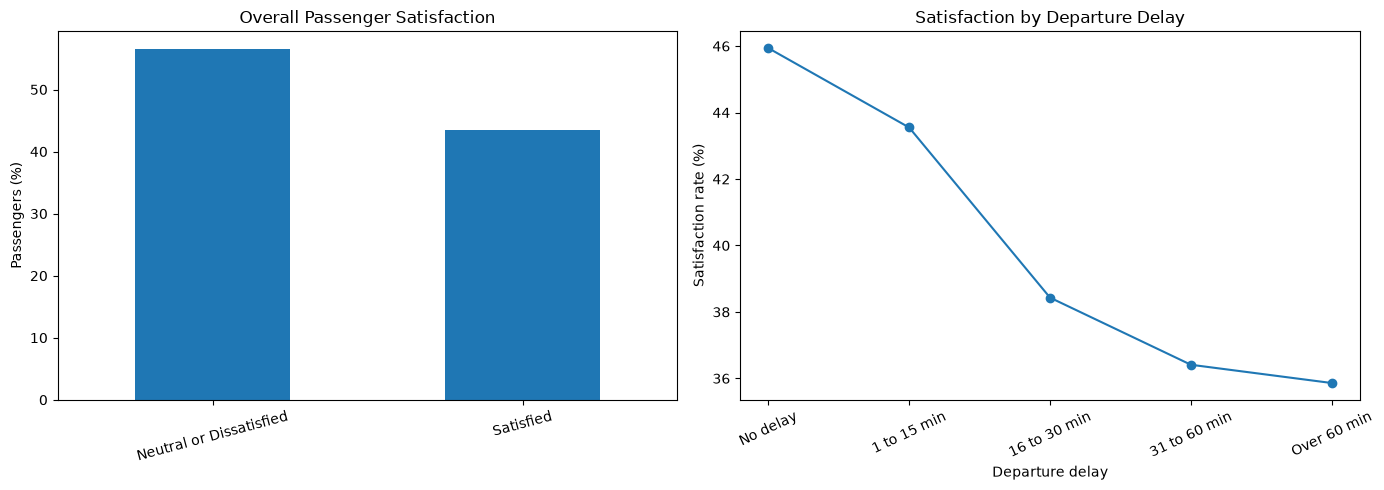

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

satisfaction_summary.plot(
    kind="bar",
    x="satisfaction",
    y="percentage",
    ax=axes[0],
    legend=False
)

axes[0].set_title("Overall Passenger Satisfaction")
axes[0].set_ylabel("Passengers (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)

axes[1].plot(
    departure_analysis["departure_delay_band"].astype(str),
    departure_analysis["satisfaction_rate_pct"],
    marker="o"
)

axes[1].set_title("Satisfaction by Departure Delay")
axes[1].set_ylabel("Satisfaction rate (%)")
axes[1].set_xlabel("Departure delay")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


In [9]:

print("BUSINESS ANALYSIS SUMMARY")
print("=" * 40)

total_passengers = len(df)
satisfied_passengers = (
    df["satisfaction"] == "Satisfied"
).sum()

print(f"Total passengers: {total_passengers:,}")
print(f"Satisfied passengers: {satisfied_passengers:,}")
print(
    f"Satisfaction rate: "
    f"{satisfied_passengers / total_passengers * 100:.2f}%"
)

print("\nHighest satisfaction by class")
display(class_analysis.head(1))

print("\nHighest satisfaction by travel type")
display(travel_analysis.head(1))

print("\nHighest satisfaction by customer type")
display(customer_analysis.head(1))

print("\nServices most associated with satisfaction")
display(service_summary.head(5))

print("\nLowest average service ratings")
display(
    service_summary.sort_values("average_rating").head(5)
)


BUSINESS ANALYSIS SUMMARY
Total passengers: 129,880
Satisfied passengers: 56,428
Satisfaction rate: 43.45%

Highest satisfaction by class


,class,total_passengers,satisfied_passengers,satisfaction_rate_pct
0,Business,62160,43166,69.44



Highest satisfaction by travel type


,type_of_travel,total_passengers,satisfied_passengers,satisfaction_rate_pct
0,Business,89693,52356,58.37



Highest satisfaction by customer type


,customer_type,total_passengers,satisfied_passengers,satisfaction_rate_pct
1,Returning,106100,50728,47.81



Services most associated with satisfaction


,average_rating,low_rating_pct,spearman_correlation
online_boarding,3.331640,49.14,0.589782
in_flight_entertainment,3.358542,47.38,0.399627
in_flight_wifi_service,2.813526,68.93,0.372214
seat_comfort,3.441388,43.86,0.361513
on_board_service,3.383153,47.49,0.328360



Lowest average service ratings


,average_rating,low_rating_pct,spearman_correlation
in_flight_wifi_service,2.813526,68.93,0.372214
ease_of_online_booking,2.883001,66.29,0.231557
gate_location,2.976948,63.14,-0.003471
food_and_drink,3.208034,54.90,0.208877
departure_and_arrival_time_convenience,3.223411,51.40,-0.048641
